**Introduction:**
Description data set

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import squarify

In [ ]:
dataset_path = "../data/1_raw/regularite-mensuelle-tgv-aqst.csv"

df_raw = pd.read_csv(dataset_path)
print(df_raw.shape)
print(df_raw.head().to_markdown())

(12544, 26)
|    | date    | service   | gare_depart        | gare_arrivee       |   duree_moyenne |   nb_train_prevu |   nb_annulation |   commentaire_annulation |   nb_train_depart_retard |   retard_moyen_depart |   retard_moyen_tous_trains_depart |   commentaire_retards_depart |   nb_train_retard_arrivee |   retard_moyen_arrivee |   retard_moyen_tous_trains_arrivee | commentaires_retard_arrivee                                                      |   nb_train_retard_sup_15 |   retard_moyen_trains_retard_sup15 |   nb_train_retard_sup_30 |   nb_train_retard_sup_60 |   prct_cause_externe |   prct_cause_infra |   prct_cause_gestion_trafic |   prct_cause_materiel_roulant |   prct_cause_gestion_gare |   prct_cause_prise_en_charge_voyageurs |
|---:|:--------|:----------|:-------------------|:-------------------|----------------:|-----------------:|----------------:|-------------------------:|-------------------------:|----------------------:|----------------------------------:|------------

In [ ]:
df_infos = pd.DataFrame(
    {
        "type": df_raw.dtypes.astype(str),
        "valeurs_distinctes": df_raw.nunique(),
        "valeurs_nulles": df_raw.isnull().sum(),
        "pourcentage_manquant": (df_raw.isnull().mean() * 100).round(2),
    }
)

print(df_infos.to_markdown())


|                                      | type    |   valeurs_distinctes |   valeurs_nulles |   pourcentage_manquant |
|:-------------------------------------|:--------|---------------------:|-----------------:|-----------------------:|
| date                                 | str     |                  102 |                0 |                   0    |
| service                              | str     |                    2 |                0 |                   0    |
| gare_depart                          | str     |                   59 |                0 |                   0    |
| gare_arrivee                         | str     |                   59 |                0 |                   0    |
| duree_moyenne                        | int64   |                  411 |                0 |                   0    |
| nb_train_prevu                       | int64   |                  903 |                0 |                   0    |
| nb_annulation                        | int64   |      

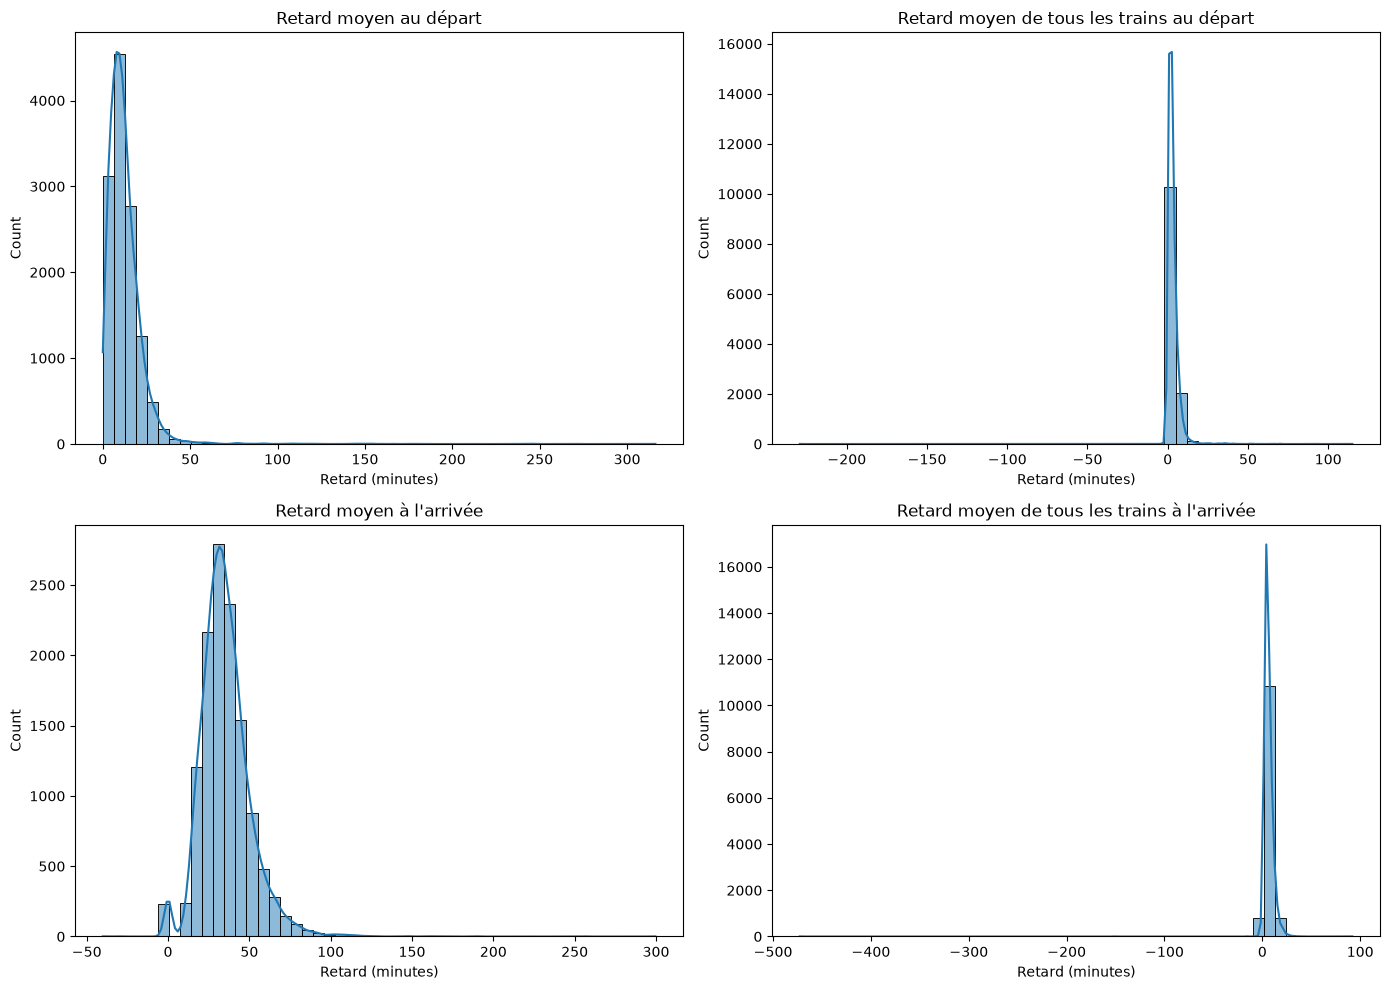

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --- DÉPART ---

sns.histplot(data=df_raw, x="retard_moyen_depart", bins=50, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Retard moyen au départ")
axes[0, 0].set_xlabel("Retard (minutes)")

sns.histplot(
    data=df_raw, x="retard_moyen_tous_trains_depart", bins=50, kde=True, ax=axes[0, 1]
)
axes[0, 1].set_title("Retard moyen de tous les trains au départ")
axes[0, 1].set_xlabel("Retard (minutes)")


# --- ARRIVÉE ---

sns.histplot(data=df_raw, x="retard_moyen_arrivee", bins=50, kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Retard moyen à l'arrivée")
axes[1, 0].set_xlabel("Retard (minutes)")

sns.histplot(
    data=df_raw, x="retard_moyen_tous_trains_arrivee", bins=50, kde=True, ax=axes[1, 1]
)
axes[1, 1].set_title("Retard moyen de tous les trains à l'arrivée")
axes[1, 1].set_xlabel("Retard (minutes)")


plt.tight_layout()
plt.show()

In [27]:
print(min(df_raw["retard_moyen_tous_trains_arrivee"]))

-472.6388889


**Impossible d'avoir un retard en négatif, et la SNCF n'est jamais en avance**

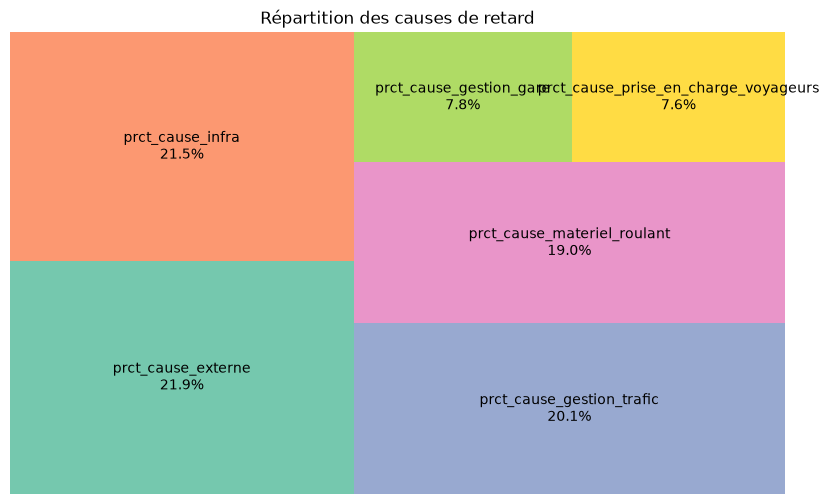

In [ ]:
cols = [
    "prct_cause_externe",
    "prct_cause_infra",
    "prct_cause_gestion_trafic",
    "prct_cause_materiel_roulant",
    "prct_cause_gestion_gare",
    "prct_cause_prise_en_charge_voyageurs",
]

values = df_raw[cols].mean()

plt.figure(figsize=(10, 6))

squarify.plot(
    sizes=values,
    label=[f"{x}\n{y:.1f}%" for x, y in zip(cols, values)],
    color=sns.color_palette("Set2", 6),
    alpha=0.9,
)

plt.axis("off")
plt.title("Répartition des causes de retard")
plt.show()

In [34]:
couples_gares = df_raw[['gare_depart', 'gare_arrivee']].drop_duplicates()
print(couples_gares.to_markdown())


|     | gare_depart                    | gare_arrivee                   |
|----:|:-------------------------------|:-------------------------------|
|   0 | BORDEAUX ST JEAN               | PARIS MONTPARNASSE             |
|   1 | LE MANS                        | PARIS MONTPARNASSE             |
|   2 | PARIS MONTPARNASSE             | LA ROCHELLE VILLE              |
|   3 | PARIS MONTPARNASSE             | NANTES                         |
|   4 | POITIERS                       | PARIS MONTPARNASSE             |
|   5 | ST MALO                        | PARIS MONTPARNASSE             |
|   6 | TOULOUSE MATABIAU              | PARIS MONTPARNASSE             |
|   7 | VANNES                         | PARIS MONTPARNASSE             |
|   8 | REIMS                          | PARIS EST                      |
|   9 | DOUAI                          | PARIS NORD                     |
|  10 | LILLE                          | PARIS NORD                     |
|  11 | LILLE                         